In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import norm

np.random.seed(42)

# Generate synthetic observations from a normal distribution
data = np.random.normal(loc=10, scale=2, size=500)

# Estimate the normal distribution parameters using maximum likelihood
mu_mle = np.mean(data)
sigma_mle = np.sqrt(np.mean((data - mu_mle) ** 2))

print("Estimated mean:", round(mu_mle, 4))
print("Estimated standard deviation:", round(sigma_mle, 4))

Estimated mean: 10.0137
Estimated standard deviation: 1.9605


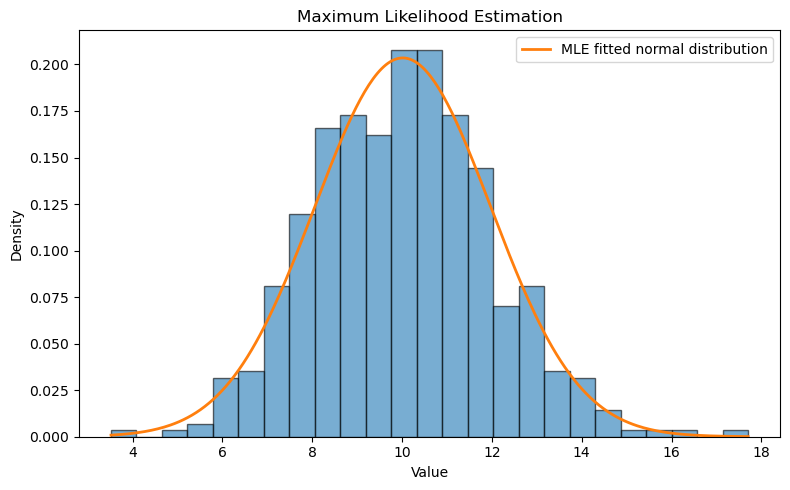

In [2]:
# Plot the observed data and fitted normal distribution
x_values = np.linspace(data.min(), data.max(), 300)
density = norm.pdf(x_values, loc=mu_mle, scale=sigma_mle)

plt.figure(figsize=(8, 5))
plt.hist(data, bins=25, density=True, alpha=0.6, edgecolor="black")
plt.plot(
    x_values,
    density,
    linewidth=2,
    label="MLE fitted normal distribution"
)

plt.xlabel("Value")
plt.ylabel("Density")
plt.title("Maximum Likelihood Estimation")
plt.legend()
plt.tight_layout()

# Save the fitted distribution plot
plt.savefig(
    "../reports/figures/mle_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
# Calculate the log-likelihood under the estimated parameters
log_likelihood = np.sum(
    norm.logpdf(data, loc=mu_mle, scale=sigma_mle)
)

print("Log-likelihood:", round(log_likelihood, 4))

Log-likelihood: -1046.08


In [4]:
# Examine how parameter estimates change with sample size
sample_sizes = [10, 25, 50, 100, 250, 500]
estimates = []

for n in sample_sizes:
    sample = data[:n]
    sample_mean = np.mean(sample)

    # Use the maximum likelihood estimator for standard deviation
    sample_std = np.sqrt(np.mean((sample - sample_mean) ** 2))

    estimates.append({
        "Sample Size": n,
        "Estimated Mean": sample_mean,
        "Estimated Std": sample_std
    })

estimates_df = pd.DataFrame(estimates)
estimates_df

,Sample Size,Estimated Mean,Estimated Std
0,10,10.896122,1.371812
1,25,9.672984,1.874454
2,50,9.549052,1.848570
3,100,9.792307,1.807232
4,250,9.995154,1.928239
5,500,10.013676,1.960543


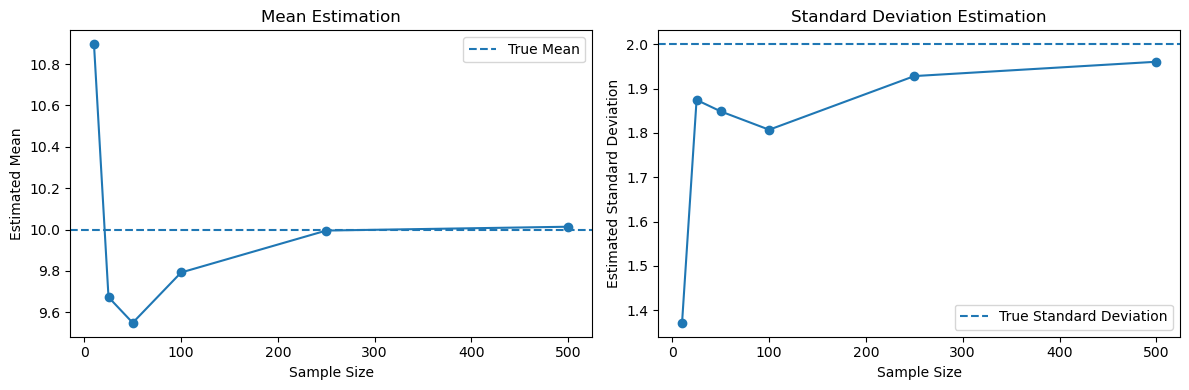

In [5]:
# Compare parameter estimates across increasing sample sizes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot estimated means
axes[0].plot(
    estimates_df["Sample Size"],
    estimates_df["Estimated Mean"],
    marker="o"
)
axes[0].axhline(10, linestyle="--", label="True Mean")
axes[0].set_xlabel("Sample Size")
axes[0].set_ylabel("Estimated Mean")
axes[0].set_title("Mean Estimation")
axes[0].legend()

# Plot estimated standard deviations
axes[1].plot(
    estimates_df["Sample Size"],
    estimates_df["Estimated Std"],
    marker="o"
)
axes[1].axhline(2, linestyle="--", label="True Standard Deviation")
axes[1].set_xlabel("Sample Size")
axes[1].set_ylabel("Estimated Standard Deviation")
axes[1].set_title("Standard Deviation Estimation")
axes[1].legend()

plt.tight_layout()

# Save the parameter estimation plots
plt.savefig(
    "../reports/figures/mle_sample_size.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [6]:
# Save parameter estimates for different sample sizes
estimates_df.to_csv(
    "../reports/mle_sample_size_results.csv",
    index=False
)

# Save the overall maximum likelihood estimates
mle_summary = pd.DataFrame({
    "Parameter": ["Mean", "Standard Deviation", "Log-Likelihood"],
    "Estimate": [mu_mle, sigma_mle, log_likelihood]
})

mle_summary.to_csv(
    "../reports/mle_summary.csv",
    index=False
)

print("MLE results saved successfully.")

MLE results saved successfully.
